# Нейросетевая классификация отклика в банковском телемаркетинге

Исследование DataForge сравнивает градиентный бустинг LightGBM и нейросетевой MLP на
табличных данных Bank Marketing (OpenML 1461): прогноз подписки на срочный депозит по
результатам телефонной кампании. Ноутбук полностью автономен: загрузка и очистка данных,
препроцессинг, обучение, подбор гиперпараметров, сравнение на тесте и анализ скрытых
представлений обученной сети.

**Задача.** Бинарная классификация: подписался ли клиент на срочный депозит после контакта.

**Источник данных.** [OpenML dataset 1461](https://www.openml.org/search?id=1461&status=any&type=data)
(версия 1, 45 211 строк, 16 входных признаков, копия UCI Bank Marketing). Исходный ARFF и
метаданные сохранены в `data/raw/`.

**Ограничения и допущения.**
- Признак `duration` (длительность последнего разговора) известен только **после** звонка: модель описывает итог уже состоявшегося контакта, а не прогноз до звонка. Использовать такую модель для отбора клиентов до обзвона нельзя.
- `pdays = -1` — значимый сентинел «клиента ранее не касались в кампании», он сохраняется как есть, а не трактуется как ошибка.
- Категориальное значение `unknown` означает пропуск и заполняется модой по train; если бы целый столбец train состоял только из `unknown`, он остался бы отдельной категорией.
- Метки в исходнике закодированы как `Class ∈ {1, 2}`; семантика сопоставлена с описанием источника (см. раздел 2): **2 = подписка** (положительный класс).
- Работа ведется на стратифицированном подмножестве 20 000 строк (seed 42).

## Содержание

1. [Окружение и подготовка](#sec-1)
2. [Источник и разведочный анализ](#sec-2)
3. [Очистка, выборка, разбиение и препроцессинг](#sec-3)
4. [Базовая линия LightGBM](#sec-4)
5. [Архитектура MLP](#sec-5)
6. [Подбор гиперпараметров и кривые обучения](#sec-6)
7. [Сравнение на тесте](#sec-7)
8. [Скрытые представления и проекции](#sec-8)
9. [Сохранение результатов и выводы](#sec-9)

## 1. Окружение и подготовка <a id="sec-1"></a>

Фиксируем seed 42 (NumPy, random, torch), определяем пути и версии библиотек.
Для обучения выбирается CUDA, если доступна, иначе CPU. При использовании GPU
включаются детерминированные настройки CUDA.

In [1]:
import copy
import hashlib
import json
import pickle
import platform
import random
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
from scipy.io import arff
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.dpi"] = 110

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW_DIR = ROOT / "data" / "raw"
PROC_DIR = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
PROC_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
print("Устройство:", DEVICE)

versions = pd.DataFrame(
    {"версия": [platform.python_version(), np.__version__, pd.__version__, sklearn.__version__,
                torch.__version__, lgb.__version__]},
    index=["python", "numpy", "pandas", "scikit-learn", "torch", "lightgbm"],
)
display(versions)

Устройство: cpu


,версия
python,3.14.7
numpy,2.5.4
pandas,2.3.3
scikit-learn,1.7.2
torch,2.15.0+cpu
lightgbm,4.7.0


## 2. Источник и разведочный анализ <a id="sec-2"></a>

Данные — Bank Marketing (телефонные кампании португальского банка, Moro, Laureano, Cortez,
2011). В исходном ARFF признаки обезличены как `V1..V16`, целевой столбец — `Class` со
значениями `1`/`2`. Восстанавливаем семантические имена по официальному описанию атрибутов
и проверяем кодировку целевого класса по распределению: в UCI-версии `y = no` встречается
39 922 раза, `y = yes` — 5 289 раз; в ARFF `Class = 1` — 39 922 строки, `Class = 2` — 5 289
строк, значит **`2` соответствует подписке** (положительный класс), `1` — отказу.

In [2]:
ARFF_PATH = RAW_DIR / "bank_marketing.arff"
SOURCE_META_PATH = RAW_DIR / "bank_marketing.metadata.json"
SAMPLE_PATH = PROC_DIR / "bank_marketing_sample.parquet"
OPENML_ID = 1461


def load_arff_frame():
    data, meta = arff.loadarff(ARFF_PATH)
    frame = pd.DataFrame(data)
    for column in frame.select_dtypes(include="object"):
        frame[column] = frame[column].str.decode("utf-8")
    return frame, meta


def fetch_openml_source():
    # Резервный путь: фактический URL файла данных берется из метаданных OpenML
    # (id файла не совпадает с id датасета и не угадывается)
    import urllib.request

    RAW_DIR.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(f"https://api.openml.org/api/v1/json/data/{OPENML_ID}", timeout=60) as response:
        description = json.loads(response.read().decode("utf-8"))["data_set_description"]
    with urllib.request.urlopen(f"https://api.openml.org/api/v1/json/data/features/{OPENML_ID}", timeout=60) as response:
        features = json.loads(response.read().decode("utf-8"))["data_features"]
    urllib.request.urlretrieve(description["url"], ARFF_PATH)
    digest = hashlib.sha256(ARFF_PATH.read_bytes()).hexdigest()
    saved = {"source": "OpenML", "dataset_id": str(OPENML_ID),
             "version": description.get("version"),
             "downloaded_at_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
             "sha256": digest,
             "original_metadata": {"data_set_description": description},
             "original_features": features}
    SOURCE_META_PATH.write_text(json.dumps(saved, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")


if ARFF_PATH.exists():
    bank_raw, arff_meta = load_arff_frame()
    print("ARFF загружен:", ARFF_PATH, bank_raw.shape)
else:
    fetch_openml_source()
    bank_raw, arff_meta = load_arff_frame()
    print("ARFF скачан по URL из метаданных OpenML и сохранен:", ARFF_PATH, bank_raw.shape)

src_meta = json.loads(SOURCE_META_PATH.read_text()) if SOURCE_META_PATH.exists() else {}
description = src_meta.get("original_metadata", {}).get("data_set_description", {}).get("description", "")
if description:
    target_fragment = "\n".join(line for line in description.splitlines()
                                 if "subscri" in line.lower() or line.startswith("17 -"))
    print("Фрагмент официального описания о целевой переменной:")
    print(target_fragment[:900])

display(pd.DataFrame({"строк": [len(bank_raw)], "столбцов (с целевым)": [bank_raw.shape[1]]}))
display(bank_raw["Class"].value_counts().sort_index().to_frame("строк").assign(
    доля=lambda d: (d["строк"] / len(bank_raw)).round(4)))
print("Сопоставление с UCI: y=no 39 922 (Class=1), y=yes 5 289 (Class=2) -> положительный класс: Class=2 (подписка)")

ARFF загружен: /home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/data/raw/bank_marketing.arff (45211, 17)
Фрагмент официального описания о целевой переменной:
The data is related with direct marketing campaigns of a Portuguese banking institution. The marketing campaigns were based on phone calls. Often, more than one contact to the same client was required, in order to access if the product (bank term deposit) would be (or not) subscribed. 
The classification goal is to predict if the client will subscribe a term deposit (variable y).
17 - y - has the client subscribed a term deposit? (binary: "yes","no")


,строк,столбцов (с целевым)
0,45211,17


,строк,доля
Class,,
1,39922,0.883
2,5289,0.117


Сопоставление с UCI: y=no 39 922 (Class=1), y=yes 5 289 (Class=2) -> положительный класс: Class=2 (подписка)


In [3]:
SEMANTIC_NAMES = {
    "V1": "age", "V2": "job", "V3": "marital", "V4": "education", "V5": "default",
    "V6": "balance", "V7": "housing", "V8": "loan", "V9": "contact", "V10": "day",
    "V11": "month", "V12": "duration", "V13": "campaign", "V14": "pdays",
    "V15": "previous", "V16": "poutcome",
}
feature_types = {name: tpe for name, tpe in zip(arff_meta.names(), arff_meta.types())}
type_table = pd.DataFrame(
    {"тип ARFF": [feature_types[c] for c in SEMANTIC_NAMES], "имя": list(SEMANTIC_NAMES.values())},
    index=list(SEMANTIC_NAMES.keys()),
)
display(type_table.T)

bank = bank_raw.rename(columns=SEMANTIC_NAMES)
NUMERIC_COLS = [SEMANTIC_NAMES[c] for c in SEMANTIC_NAMES if feature_types[c] == "numeric"]
CATEGORICAL_COLS = [SEMANTIC_NAMES[c] for c in SEMANTIC_NAMES if feature_types[c] == "nominal"]
print("Числовые признаки:", NUMERIC_COLS)
print("Категориальные признаки:", CATEGORICAL_COLS)

bank["subscribed"] = (bank["Class"] == "2").astype(np.int64)
bank = bank.drop(columns=["Class"])
display(bank[NUMERIC_COLS].describe().T.round(2))

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16
тип ARFF,numeric,nominal,nominal,nominal,nominal,numeric,nominal,nominal,nominal,numeric,nominal,numeric,numeric,numeric,numeric,nominal
имя,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome


Числовые признаки: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Категориальные признаки: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


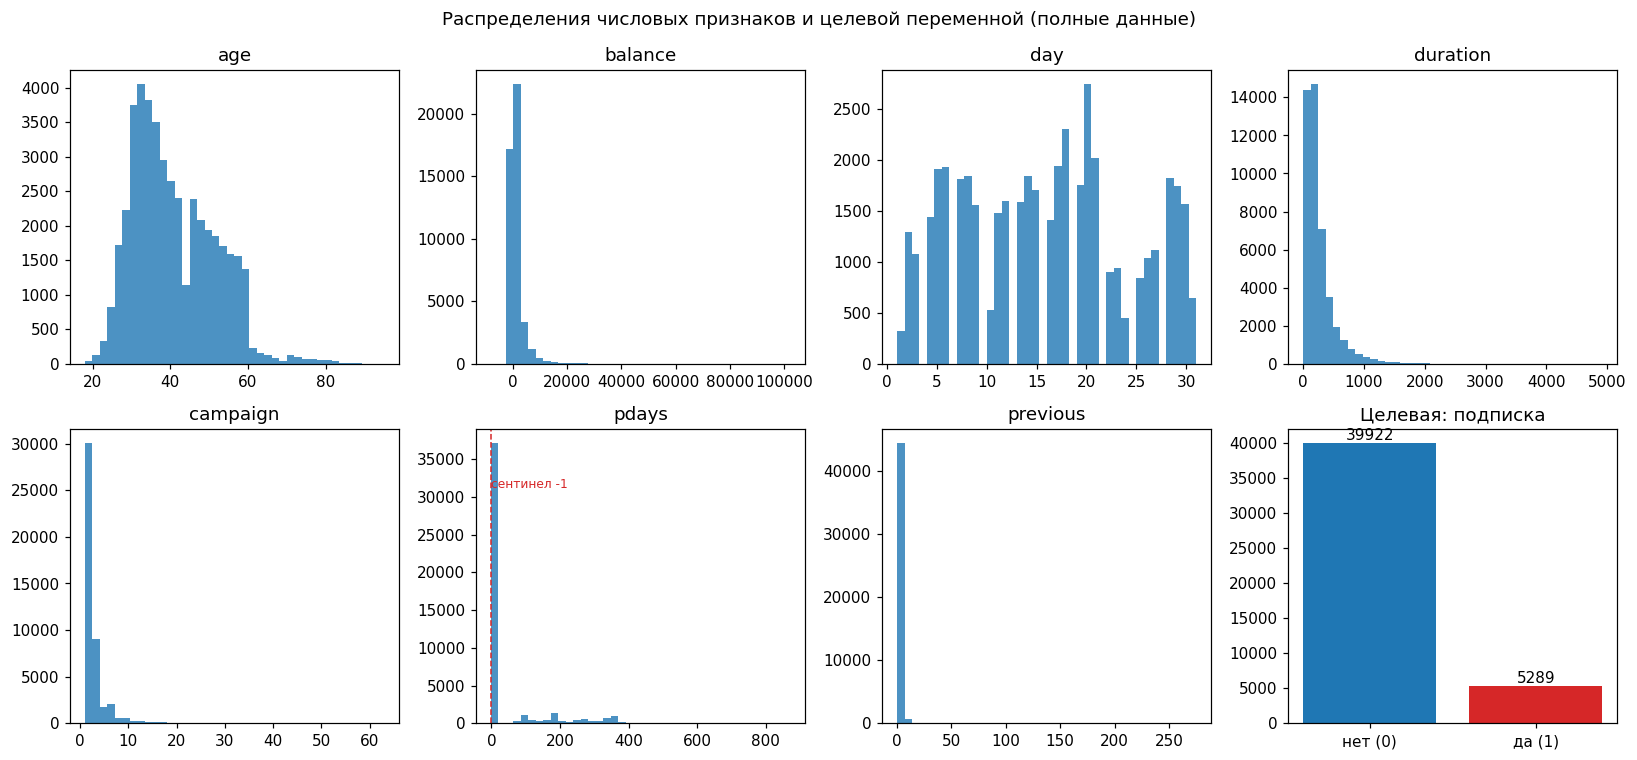

,строк 'unknown',доля
job,288.000000,0.006400
education,1857.000000,0.041100
contact,13020.000000,0.288000
poutcome,36959.000000,0.817500


pdays = -1 (клиент не участвовал в прошлых кампаниях): 36954 строк (81.7%)
duration: медиана 180 с; признак известен только ПОСЛЕ звонка


In [4]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.flat, NUMERIC_COLS + ["subscribed"]):
    if col == "subscribed":
        counts = bank["subscribed"].value_counts().sort_index()
        ax.bar(["нет (0)", "да (1)"], counts.values, color=["#1f77b4", "#d62728"])
        ax.set_title("Целевая: подписка")
        for i, v in enumerate(counts.values):
            ax.text(i, v, str(v), ha="center", va="bottom")
    else:
        ax.hist(bank[col], bins=40, color="#1f77b4", alpha=0.8)
        ax.set_title(col)
        if col == "pdays":
            ax.axvline(-1, color="#d62728", linestyle="--", linewidth=1)
            ax.annotate("сентинел -1", xy=(-1, ax.get_ylim()[1] * 0.8), fontsize=8, color="#d62728")
plt.suptitle("Распределения числовых признаков и целевой переменной (полные данные)")
plt.tight_layout()
plt.show()

unknown_counts = {
    col: {"строк 'unknown'": int((bank[col] == "unknown").sum()),
          "доля": round(float((bank[col] == "unknown").mean()), 4)}
    for col in CATEGORICAL_COLS if (bank[col] == "unknown").any()
}
display(pd.DataFrame(unknown_counts).T.style.set_caption("Категориальные значения 'unknown' (пропуски)"))
print(f"pdays = -1 (клиент не участвовал в прошлых кампаниях): {int((bank['pdays'] == -1).sum())} строк "
      f"({(bank['pdays'] == -1).mean():.1%})")
print(f"duration: медиана {bank['duration'].median():.0f} с; признак известен только ПОСЛЕ звонка")

## 3. Очистка, выборка, разбиение и препроцессинг <a id="sec-3"></a>

Готовая стратифицированная выборка 20 000 строк (seed 42) подготовлена после удаления
точных дубликатов исходных данных и хранится под контролем DVC в
`data/processed/bank_marketing_sample.parquet`. Перед запуском файл должен быть
получен из DVC (инструкции в README). Ноутбук загружает выборку и делит ее
стратифицированно 60/20/20 на train/validation/test. Препроцессинг обучается
только на train: медиана для числовых пропусков + `StandardScaler`; для категорий
`unknown` → пропуск → мода train; кодирование категорий отдельным словарем на столбец,
известные значения получают коды 1..K, код 0 зарезервирован для unseen-значений.


In [5]:
bank_raw["source_row"] = np.arange(len(bank_raw), dtype=np.int64)
source_columns = [c for c in bank_raw.columns if c != "source_row"]
n_full = len(bank_raw)
bank_raw_dedup = bank_raw.drop_duplicates(subset=source_columns)
print(f"Точных дубликатов удалено: {n_full - len(bank_raw_dedup)} (осталось {len(bank_raw_dedup)})")


bank_sample_raw = pd.read_parquet(SAMPLE_PATH)
print("Выборка загружена:", SAMPLE_PATH)
print("Схема сохраненной выборки:", list(bank_sample_raw.columns))

bank_sample = bank_sample_raw.rename(columns=SEMANTIC_NAMES)
bank_sample["subscribed"] = (bank_sample["Class"] == "2").astype(np.int64)
bank_sample = bank_sample.drop(columns=["Class"])

display(bank_sample["subscribed"].value_counts().sort_index().to_frame("строк")
        .assign(доля=lambda d: (d["строк"] / len(bank_sample)).round(4)))

idx = np.arange(len(bank_sample))
idx_trainval, idx_test = train_test_split(
    idx, test_size=0.2, stratify=bank_sample["subscribed"], random_state=SEED)
idx_train, idx_val = train_test_split(
    idx_trainval, test_size=0.25, stratify=bank_sample["subscribed"].iloc[idx_trainval],
    random_state=SEED)
splits = {
    "train": bank_sample.iloc[np.sort(idx_train)].reset_index(drop=True),
    "validation": bank_sample.iloc[np.sort(idx_val)].reset_index(drop=True),
    "test": bank_sample.iloc[np.sort(idx_test)].reset_index(drop=True),
}
for name, part in splits.items():
    pos = int(part["subscribed"].sum())
    print(f"{name}: {len(part)} строк, положительных {pos} ({pos / len(part):.3%})")

split_frames = []
for name, part in splits.items():
    saved = part[["source_row", "subscribed"]].copy()
    saved["split"] = name
    split_frames.append(saved)
splits_path = PROC_DIR / "bank_splits.parquet"
pd.concat(split_frames, ignore_index=True).to_parquet(splits_path, index=False)
print("Идентификаторы разбиения сохранены:", splits_path)

Точных дубликатов удалено: 0 (осталось 45211)
Выборка загружена: /home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/data/processed/bank_marketing_sample.parquet
Схема сохраненной выборки: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'Class', 'source_row']


,строк,доля
subscribed,,
0,17660,0.883
1,2340,0.117


train: 12000 строк, положительных 1404 (11.700%)
validation: 4000 строк, положительных 468 (11.700%)
test: 4000 строк, положительных 468 (11.700%)
Идентификаторы разбиения сохранены: /home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/data/processed/bank_splits.parquet


In [6]:
# Препроцессинг: все статистики считаются ТОЛЬКО на train
medians = splits["train"][NUMERIC_COLS].median()
scaler = StandardScaler().fit(splits["train"][NUMERIC_COLS].fillna(medians).to_numpy(dtype=np.float32))

train_unknown_masked = {col: splits["train"][col].replace("unknown", np.nan) for col in CATEGORICAL_COLS}
modes = {}
for col in CATEGORICAL_COLS:
    column = train_unknown_masked[col]
    modes[col] = column.dropna().mode().iloc[0] if column.notna().any() else None
all_missing_columns = [col for col, m in modes.items() if m is None]
print("Столбцы целиком из 'unknown' на train (значение 'unknown' остается конкретной категорией):",
      all_missing_columns if all_missing_columns else "нет")
print("Моды для заполнения 'unknown':", {k: v for k, v in modes.items() if v is not None})

cat_frames = {}
for name, part in splits.items():
    frame = pd.DataFrame(index=part.index)
    for col in CATEGORICAL_COLS:
        if modes[col] is None:
            frame[col] = part[col]
        else:
            frame[col] = part[col].replace("unknown", np.nan).fillna(modes[col])
    cat_frames[name] = frame

cat_codes = {}
for col in CATEGORICAL_COLS:
    values = sorted(cat_frames["train"][col].astype(str).unique())
    cat_codes[col] = {v: i + 1 for i, v in enumerate(values)}
print("Мощности категорий (код 0 зарезервирован под unseen):",
      {col: len(codes) for col, codes in cat_codes.items()})

X_num, X_cat, y = {}, {}, {}
for name, part in splits.items():
    X_num[name] = scaler.transform(part[NUMERIC_COLS].fillna(medians).to_numpy(dtype=np.float64)).astype(np.float32)
    encoded = np.zeros((len(part), len(CATEGORICAL_COLS)), dtype=np.int64)
    for j, col in enumerate(CATEGORICAL_COLS):
        encoded[:, j] = (cat_frames[name][col].astype(str).map(cat_codes[col])
                         .fillna(0).astype(np.int64).to_numpy())
    X_cat[name] = encoded
    y[name] = part["subscribed"].to_numpy(dtype=np.float32)

for name in splits:
    print(f"{name}: числовые {X_num[name].shape} {X_num[name].dtype}, "
          f"категории {X_cat[name].shape} {X_cat[name].dtype}, "
          f"unseen-кодов вне train: {int((X_cat[name] == 0).sum())}")

Столбцы целиком из 'unknown' на train (значение 'unknown' остается конкретной категорией): нет
Моды для заполнения 'unknown': {'job': 'blue-collar', 'marital': 'married', 'education': 'secondary', 'default': 'no', 'housing': 'yes', 'loan': 'no', 'contact': 'cellular', 'month': 'may', 'poutcome': 'failure'}


Мощности категорий (код 0 зарезервирован под unseen): {'job': 11, 'marital': 3, 'education': 3, 'default': 2, 'housing': 2, 'loan': 2, 'contact': 2, 'month': 12, 'poutcome': 3}


train: числовые (12000, 7) float32, категории (12000, 9) int64, unseen-кодов вне train: 0
validation: числовые (4000, 7) float32, категории (4000, 9) int64, unseen-кодов вне train: 0
test: числовые (4000, 7) float32, категории (4000, 9) int64, unseen-кодов вне train: 0


## 4. Базовая линия LightGBM <a id="sec-4"></a>

LightGBM с параметрами обучения по умолчанию, `seed=42`, CPU-потоки ограничены двумя,
подробный лог отключен. Конвейер принимает исходный DataFrame с семантическими
столбцами: замена `unknown` → NaN выполняется внутри конвейера (`FunctionTransformer`
над `pd.DataFrame.replace`), далее медиана для числовых и мода + one-hot
(`handle_unknown='ignore'`) для категорий; столбцы целиком из `unknown` проходят как
отдельная категория, как и у MLP. Вся предобработка обучается только на train,
разбиение и признаки те же, что у MLP; сохраненный pickle самодостаточен.
Дорогой поиск гиперпараметров не проводится.

In [7]:
boosting_features = NUMERIC_COLS + CATEGORICAL_COLS
unknown_replacements = {col: "unknown" for col in CATEGORICAL_COLS if modes[col] is not None}
unknown_to_nan = FunctionTransformer(
    pd.DataFrame.replace,
    kw_args={"to_replace": unknown_replacements, "value": np.nan},
)
lgbm_model = Pipeline([
    ("unknown_to_nan", unknown_to_nan),
    ("preprocess", ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUMERIC_COLS),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
        ]), CATEGORICAL_COLS),
    ])),
    ("model", lgb.LGBMClassifier(random_state=SEED, n_jobs=2, verbosity=-1)),
])
t0 = time.perf_counter()
lgbm_model.fit(splits["train"][boosting_features], splits["train"]["subscribed"])
t_lgbm_fit = time.perf_counter() - t0
val_prob_lgbm = lgbm_model.predict_proba(splits["validation"][boosting_features])[:, 1]
val_auc_lgbm = roc_auc_score(splits["validation"]["subscribed"], val_prob_lgbm)
print(f"LightGBM обучен за {t_lgbm_fit:.1f} с; ROC-AUC на валидации: {val_auc_lgbm:.4f}")
n_features_lgbm = len(lgbm_model.named_steps["model"].feature_name_)
print("Число признаков после one-hot:", n_features_lgbm)

LightGBM обучен за 0.3 с; ROC-AUC на валидации: 0.9241
Число признаков после one-hot: 47


## 5. Архитектура MLP <a id="sec-5"></a>

Собственный `nn.Module`: каждый категориальный признак проходит через `nn.Embedding`
(число строк = мощность категории + 1 с учетом зарезервированного кода 0 для unseen;
размерность `min(50, (мощность + 1) // 2)`; столбец целиком из `unknown` получает
конкретную категорию `unknown`), эмбеддинги конкатенируются со стандартизованными
числовыми признаками. Далее скрытые блоки `Linear -> BatchNorm1d -> ReLU -> Dropout`,
выход — один логит (BCEWithLogitsLoss). Скрытое представление для анализа — активация
последнего скрытого слоя в eval-режиме. Модель, функция потерь, веса классов и все
мини-батчи переносятся на доступное устройство (`DEVICE`); в этом окружении torch —
CPU-сборка (CUDA недоступна), поэтому фактическое выполнение шло на
CPU, а GPU-ветка на этой машине не проверялась.

In [8]:
class BankMLP(nn.Module):
    def __init__(self, categorical_cardinalities, n_numeric, hidden_sizes, dropout):
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality + 1, min(50, (cardinality + 1) // 2))
            for cardinality in categorical_cardinalities
        ])
        emb_dim = sum(emb.embedding_dim for emb in self.embeddings)
        input_dim = emb_dim + n_numeric
        blocks = []
        width = input_dim
        for h in hidden_sizes:
            blocks.extend([nn.Linear(width, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)])
            width = h
        self.hidden = nn.Sequential(*blocks)
        self.output = nn.Linear(width, 1)

    def forward(self, x_cat, x_num):
        embedded = [emb(x_cat[:, i]) for i, emb in enumerate(self.embeddings)]
        z = torch.cat(embedded + [x_num], dim=1)
        return self.output(self.hidden(z)).squeeze(1)

    def forward_hidden(self, x_cat, x_num):
        # Активация после последнего скрытого слоя (eval-режим задается снаружи)
        embedded = [emb(x_cat[:, i]) for i, emb in enumerate(self.embeddings)]
        z = torch.cat(embedded + [x_num], dim=1)
        for layer in list(self.hidden)[:-1]:
            z = layer(z)
        return z


cardinalities = [len(cat_codes[col]) for col in CATEGORICAL_COLS]
embedding_table = pd.DataFrame(
    {"мощность (K)": cardinalities,
     "размерность": [min(50, (k + 1) // 2) for k in cardinalities]},
    index=CATEGORICAL_COLS,
)
display(embedding_table.T.style.set_caption("Параметры эмбеддингов"))

demo = BankMLP(cardinalities, len(NUMERIC_COLS), hidden_sizes=(128, 64), dropout=0.2)
print(f"Пример архитектуры (128, 64), dropout 0.2: параметров {sum(p.numel() for p in demo.parameters()):,}")

,job,marital,education,default,housing,loan,contact,month,poutcome
мощность (K),11,3,3,2,2,2,2,12,3
размерность,6,2,2,1,1,1,1,6,2


Пример архитектуры (128, 64), dropout 0.2: параметров 12,731


## 6. Подбор гиперпараметров и кривые обучения <a id="sec-6"></a>

DataLoader: батч 128, перемешивание train с отдельным сеяным генератором, `drop_last=True`
в train, чтобы BatchNorm не встречал одиночный батч. Оптимизатор Adam,
`BCEWithLogitsLoss(pos_weight = neg/pos)`, весовой коэффициент считается только на train.
Максимум 30 эпох, ранняя остановка с терпением 5 по ROC-AUC валидации, восстановление
лучшего чекпоинта. Ровно 12 конфигураций: ширины `[(64,), (128,64), (128,64,32)]` ×
dropout `[0.2, 0.4]` × learning rate `[0.001, 0.0003]`; модель, оптимизатор и seed
сбрасываются на каждую конфигурацию. Выбор — только по валидации, тест не участвует.

In [9]:
def make_loader(name, shuffle, batch_size, drop_last):
    dataset = TensorDataset(torch.from_numpy(X_cat[name]), torch.from_numpy(X_num[name]),
                            torch.from_numpy(y[name]))
    generator = None
    if shuffle:
        generator = torch.Generator()
        generator.manual_seed(SEED)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      drop_last=drop_last, generator=generator)


def make_train_loader():
    # Свой сеяный генератор на каждую конфигурацию: перемешивание одинаково
    # воспроизводится независимо от порядка запуска конфигураций
    dataset = TensorDataset(torch.from_numpy(X_cat["train"]), torch.from_numpy(X_num["train"]),
                            torch.from_numpy(y["train"]))
    generator = torch.Generator()
    generator.manual_seed(SEED)
    return DataLoader(dataset, batch_size=128, shuffle=True, drop_last=True, generator=generator)


val_loader = make_loader("validation", False, 512, False)

n_pos_train = float((y["train"] == 1).sum())
n_neg_train = float((y["train"] == 0).sum())
pos_weight = torch.tensor([n_neg_train / n_pos_train], dtype=torch.float32, device=DEVICE)
print(f"train: позитивных {int(n_pos_train)}, негативных {int(n_neg_train)}, pos_weight = {pos_weight.item():.3f}")


def evaluate_split(model, name, loss_fn):
    model.eval()
    logits_parts, loss_sum, n_seen = [], 0.0, 0
    with torch.no_grad():
        for x_cat, x_num, target in make_loader(name, False, 512, False):
            logits = model(x_cat.to(DEVICE), x_num.to(DEVICE))
            loss_sum += float(loss_fn(logits, target.to(DEVICE)).item()) * len(target)
            n_seen += len(target)
            logits_parts.append(logits.detach().cpu().numpy())
    logits_all = np.concatenate(logits_parts)
    return loss_sum / n_seen, roc_auc_score(y[name], logits_all), logits_all


def train_config(hidden_sizes, dropout, lr, max_epochs=30, patience=5):
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(SEED)
    model = BankMLP(cardinalities, len(NUMERIC_COLS), hidden_sizes, dropout).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    loader = make_train_loader()
    best_auc, best_state, bad_epochs = -1.0, None, 0
    history = {"train_loss": [], "val_loss": [], "val_auc": []}
    t0 = time.perf_counter()
    epochs_done = 0
    for epoch in range(max_epochs):
        model.train()
        batch_losses = []
        for x_cat, x_num, target in loader:
            x_cat, x_num, target = x_cat.to(DEVICE), x_num.to(DEVICE), target.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(x_cat, x_num), target)
            loss.backward()
            optimizer.step()
            batch_losses.append(float(loss.item()))
        val_loss, val_auc, _ = evaluate_split(model, "validation", loss_fn)
        history["train_loss"].append(float(np.mean(batch_losses)))
        history["val_loss"].append(val_loss)
        history["val_auc"].append(val_auc)
        epochs_done = epoch + 1
        if val_auc > best_auc:
            best_auc = val_auc
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                break
    seconds = time.perf_counter() - t0
    model.load_state_dict(best_state)
    return model, best_auc, seconds, epochs_done, history


CONFIGS = [
    (hidden, dropout, lr)
    for hidden in [(64,), (128, 64), (128, 64, 32)]
    for dropout in [0.2, 0.4]
    for lr in [0.001, 0.0003]
]
print(f"Конфигураций к обучению: {len(CONFIGS)}")

config_results = []
config_models = {}
config_histories = {}
config_specs = {}
for number, (hidden, dropout, lr) in enumerate(CONFIGS, start=1):
    model, auc_value, seconds, epochs_done, history = train_config(hidden, dropout, lr)
    label = f"{hidden} d={dropout} lr={lr}"
    config_results.append({"конфигурация": label, "val_roc_auc": auc_value,
                           "эпох": epochs_done, "время, с": seconds})
    config_models[label] = model
    config_histories[label] = history
    config_specs[label] = {"hidden": list(hidden), "dropout": dropout, "lr": lr}
    print(f"[{number:02d}/12] {label}: val ROC-AUC {auc_value:.4f}, эпох {epochs_done}, {seconds:.0f} с")

configs_table = pd.DataFrame(config_results)
display(configs_table.round({"val_roc_auc": 4, "время, с": 1})
        .style.set_caption("Все 12 конфигураций (выбор по валидации)"))

train: позитивных 1404, негативных 10596, pos_weight = 7.547
Конфигураций к обучению: 12


[01/12] (64,) d=0.2 lr=0.001: val ROC-AUC 0.9136, эпох 16, 7 с


[02/12] (64,) d=0.2 lr=0.0003: val ROC-AUC 0.9126, эпох 30, 12 с


[03/12] (64,) d=0.4 lr=0.001: val ROC-AUC 0.9154, эпох 30, 13 с


[04/12] (64,) d=0.4 lr=0.0003: val ROC-AUC 0.9122, эпох 30, 13 с


[05/12] (128, 64) d=0.2 lr=0.001: val ROC-AUC 0.9135, эпох 9, 5 с


... (4 outputs left out)

[10/12] (128, 64, 32) d=0.2 lr=0.0003: val ROC-AUC 0.9132, эпох 22, 12 с


[11/12] (128, 64, 32) d=0.4 lr=0.001: val ROC-AUC 0.9126, эпох 16, 9 с


[12/12] (128, 64, 32) d=0.4 lr=0.0003: val ROC-AUC 0.9128, эпох 30, 17 с


,конфигурация,val_roc_auc,эпох,"время, с"
0,"(64,) d=0.2 lr=0.001",0.913600,16,7.000000
1,"(64,) d=0.2 lr=0.0003",0.912600,30,12.500000
2,"(64,) d=0.4 lr=0.001",0.915400,30,12.600000
3,"(64,) d=0.4 lr=0.0003",0.912200,30,12.800000
4,"(128, 64) d=0.2 lr=0.001",0.913500,9,5.100000
5,"(128, 64) d=0.2 lr=0.0003",0.912900,18,9.500000
6,"(128, 64) d=0.4 lr=0.001",0.913100,16,8.400000
7,"(128, 64) d=0.4 lr=0.0003",0.913600,30,16.200000
8,"(128, 64, 32) d=0.2 lr=0.001",0.913600,9,4.800000
9,"(128, 64, 32) d=0.2 lr=0.0003",0.913200,22,12.100000


Лучшая конфигурация по валидации: (64,) d=0.4 lr=0.001


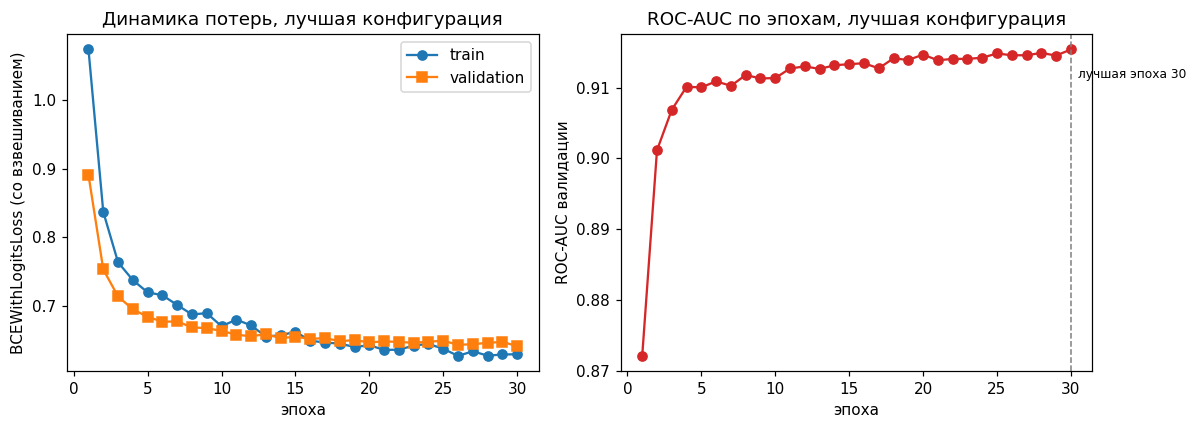

Лучшая эпоха: 30, восстановлен чекпоинт этой эпохи


In [10]:
best_label = configs_table.loc[configs_table["val_roc_auc"].idxmax(), "конфигурация"]
best_model = config_models[best_label]
best_history = config_histories[best_label]
print("Лучшая конфигурация по валидации:", best_label)

epochs_axis = np.arange(1, len(best_history["val_auc"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs_axis, best_history["train_loss"], marker="o", label="train")
axes[0].plot(epochs_axis, best_history["val_loss"], marker="s", label="validation")
axes[0].set_xlabel("эпоха")
axes[0].set_ylabel("BCEWithLogitsLoss (со взвешиванием)")
axes[0].set_title("Динамика потерь, лучшая конфигурация")
axes[0].legend()
axes[1].plot(epochs_axis, best_history["val_auc"], marker="o", color="#d62728")
axes[1].set_xlabel("эпоха")
axes[1].set_ylabel("ROC-AUC валидации")
axes[1].set_title("ROC-AUC по эпохам, лучшая конфигурация")
best_epoch = int(np.argmax(best_history["val_auc"]) + 1)
axes[1].axvline(best_epoch, color="gray", linestyle="--", linewidth=1)
axes[1].annotate(f"лучшая эпоха {best_epoch}", xy=(best_epoch, max(best_history["val_auc"])),
                 xytext=(best_epoch + 0.5, max(best_history["val_auc"]) - 0.004), fontsize=8)
plt.tight_layout()
plt.show()
print(f"Лучшая эпоха: {best_epoch}, восстановлен чекпоинт этой эпохи")

## 7. Сравнение на тесте <a id="sec-7"></a>

Выбранный по валидации чекпоинт MLP и LightGBM оцениваются на отложенном тесте: ROC-AUC,
average precision, accuracy, F1, precision, recall (порог 0.5), матрицы ошибок и время
обучения. Из-за несбалансированности классов (~11,7% позитивных) accuracy малоинформативна,
приоритет — ROC-AUC и PR-метрикам.

,ROC-AUC,AP (average precision),accuracy,F1,precision,recall
MLP (лучшая конфигурация),0.9087,0.5241,0.8082,0.5179,0.3669,0.8803
LightGBM (по умолчанию),0.9145,0.5611,0.9012,0.5006,0.6130,0.4231


,"время обучения, с"
MLP (все 12 конфигураций),126.7
LightGBM,0.3


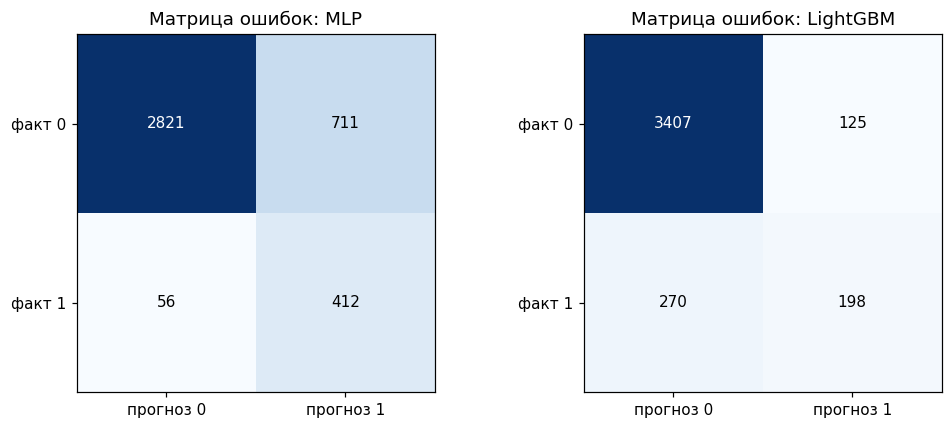

Класс 1 — подписка (положительный, ~11,7% строк)


In [11]:
def mlp_probabilities(model, name):
    model.eval()
    parts = []
    with torch.no_grad():
        for x_cat, x_num, _ in make_loader(name, False, 512, False):
            logits = model(x_cat.to(DEVICE), x_num.to(DEVICE))
            parts.append(torch.sigmoid(logits).detach().cpu().numpy())
    return np.concatenate(parts)


def full_metrics(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, proba),
            "AP (average precision)": average_precision_score(y_true, proba),
            "accuracy": accuracy_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0)}


test_prob_mlp = mlp_probabilities(best_model, "test")
test_prob_lgbm = lgbm_model.predict_proba(splits["test"][boosting_features])[:, 1]
y_test = splits["test"]["subscribed"].to_numpy()

test_metrics = pd.DataFrame(
    {"MLP (лучшая конфигурация)": full_metrics(y_test, test_prob_mlp),
     "LightGBM (по умолчанию)": full_metrics(y_test, test_prob_lgbm)}
).T.round(4)
display(test_metrics.style.format("{:.4f}").set_caption("Метрики на тесте (порог 0.5, n = 4 000)"))

fit_times = pd.DataFrame(
    {"время обучения, с": [round(np.sum([r["время, с"] for r in config_results]), 1), round(t_lgbm_fit, 1)]},
    index=["MLP (все 12 конфигураций)", "LightGBM"],
)
display(fit_times)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
for ax, (name, proba) in zip(axes, [("MLP", test_prob_mlp), ("LightGBM", test_prob_lgbm)]):
    cm = confusion_matrix(y_test, (proba >= 0.5).astype(int))
    image = ax.imshow(cm, cmap="Blues")
    for r in range(cm.shape[0]):
        for c in range(cm.shape[1]):
            ax.text(c, r, str(cm[r, c]), ha="center", va="center",
                    color="white" if cm[r, c] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["прогноз 0", "прогноз 1"])
    ax.set_yticks([0, 1], ["факт 0", "факт 1"])
    ax.set_title(f"Матрица ошибок: {name}")
plt.tight_layout()
plt.show()
print("Класс 1 — подписка (положительный, ~11,7% строк)")

## 8. Скрытые представления и проекции <a id="sec-8"></a>

Извлекается активация последнего скрытого слоя обученной выбранной сети (eval-режим) для
train и тестовых объектов. PCA обучается только на train-представлениях
(`n_components = min(50, размерность, n_train − 1)`), выводится суммарная объясненная
дисперсия. Одни и те же до 2 000 стратифицированных тестовых объектов (seed 42)
показываются на трех диаграммах: первые две компоненты PCA, t-SNE и UMAP на
PCA-сокращенном представлении (t-SNE: `perplexity=30, init='pca', learning_rate='auto'`;
UMAP: `n_neighbors=15, min_dist=0.1`; оба `random_state=42`). Метки классов задают только
цвет, в подгонку UMAP не передаются.

Скрытые представления: train (12000, 64), test (4000, 64)
Компонент PCA: 50; суммарная объясненная дисперсия: 0.9875
Объектов теста для проекций: 2000 (стратифицированно, seed 42)


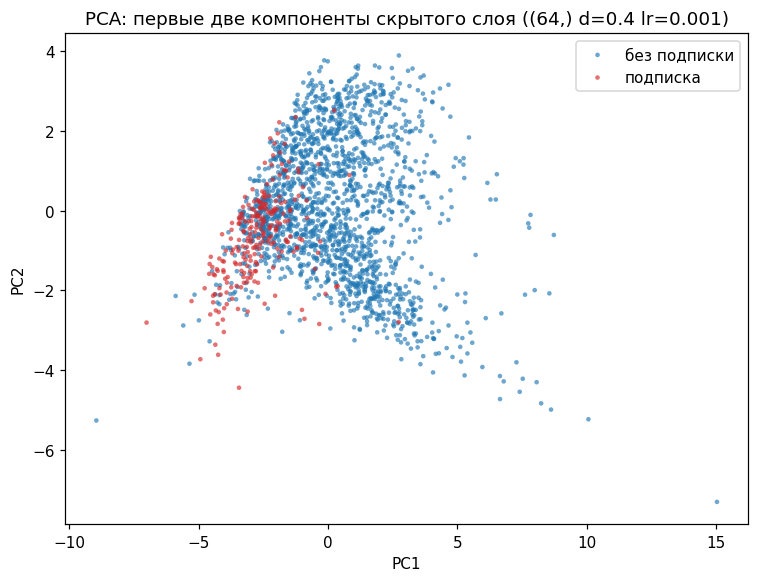

In [12]:
def hidden_representation(model, name):
    model.eval()
    parts = []
    with torch.no_grad():
        for x_cat, x_num, _ in make_loader(name, False, 512, False):
            parts.append(model.forward_hidden(x_cat.to(DEVICE), x_num.to(DEVICE)).detach().cpu().numpy())
    return np.concatenate(parts).astype(np.float32)


H_train = hidden_representation(best_model, "train")
H_test = hidden_representation(best_model, "test")
print(f"Скрытые представления: train {H_train.shape}, test {H_test.shape}")

n_components = min(50, H_train.shape[1], len(H_train) - 1)
pca = PCA(n_components=n_components, random_state=SEED).fit(H_train)
print(f"Компонент PCA: {n_components}; суммарная объясненная дисперсия: {pca.explained_variance_ratio_.sum():.4f}")

if len(y_test) > 2000:
    sel, _ = train_test_split(np.arange(len(y_test)), train_size=2000,
                              stratify=y_test, random_state=SEED)
    sel = np.sort(sel)
else:
    sel = np.arange(len(y_test))
print(f"Объектов теста для проекций: {len(sel)} (стратифицированно, seed {SEED})")
Z_test = pca.transform(H_test[sel])
y_sel = y_test[sel]

CLASS_COLORS = {0: "#1f77b4", 1: "#d62728"}
CLASS_LABELS = {0: "без подписки", 1: "подписка"}

fig, ax = plt.subplots(figsize=(7, 5.4))
for label in (0, 1):
    mask = y_sel == label
    ax.scatter(Z_test[mask, 0], Z_test[mask, 1], s=9, alpha=0.65,
               color=CLASS_COLORS[label], label=CLASS_LABELS[label], edgecolors="none")
ax.set_title(f"PCA: первые две компоненты скрытого слоя ({best_label})")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend()
plt.tight_layout()
plt.show()

t-SNE завершен за 5 с


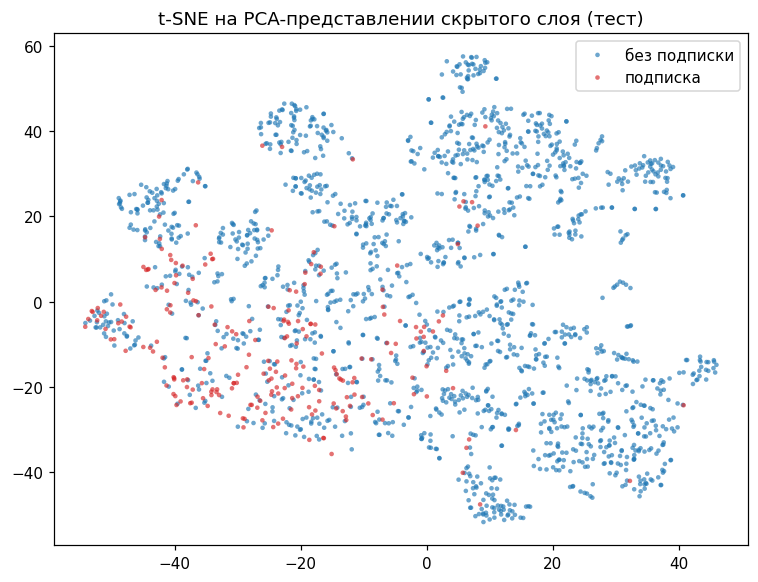

In [13]:
t0 = time.perf_counter()
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED)
T_test = tsne.fit_transform(Z_test)
print(f"t-SNE завершен за {time.perf_counter() - t0:.0f} с")

fig, ax = plt.subplots(figsize=(7, 5.4))
for label in (0, 1):
    mask = y_sel == label
    ax.scatter(T_test[mask, 0], T_test[mask, 1], s=9, alpha=0.65,
               color=CLASS_COLORS[label], label=CLASS_LABELS[label], edgecolors="none")
ax.set_title("t-SNE на PCA-представлении скрытого слоя (тест)")
ax.legend()
plt.tight_layout()
plt.show()

/home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP завершен за 16 с


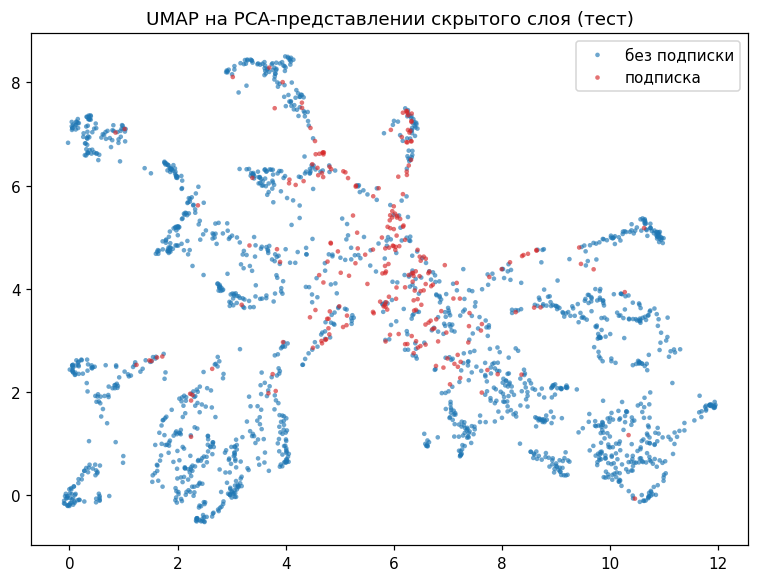

In [14]:
import umap

t0 = time.perf_counter()
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED)
U_test = reducer.fit_transform(Z_test)
print(f"UMAP завершен за {time.perf_counter() - t0:.0f} с")

fig, ax = plt.subplots(figsize=(7, 5.4))
for label in (0, 1):
    mask = y_sel == label
    ax.scatter(U_test[mask, 0], U_test[mask, 1], s=9, alpha=0.65,
               color=CLASS_COLORS[label], label=CLASS_LABELS[label], edgecolors="none")
ax.set_title("UMAP на PCA-представлении скрытого слоя (тест)")
ax.legend()
plt.tight_layout()
plt.show()

### Интерпретация проекций

- Классы подписки существенно **перекрываются**: большинство подписавшихся клиентов не
  образуют отдельного «острова», а рассеяны среди отказавшихся. При измеренном качестве
  (ROC-AUC ≈ 0,90–0,91 на тесте) идеального разделения нет, но перекрытие в 2D не отражает
  реальную разделимость в пространстве всех измерений.
- Отдельные плотные сгустки и разреженные области могут объясняться редкими комбинациями
  категорий или экстремальными числовыми значениями, однако по построенным диаграммам это
  не устанавливается: такие объяснения остаются **непроверенными гипотезами**, для которых
  нужен анализ признаков самих объектов; удаленные точки — кандидаты в выбросы.
- Важно: скрытое представление обучалось **с использованием меток** (сеть видела
  `subscribed` при обучении), поэтому геометрия уже «подстроена» под классы —
  разделимость на диаграммах нельзя интерпретировать как «естественную» кластеризацию.
- Двумерные проекции искажают расстояния: перекрытие или кластеры в 2D не доказывают
  линейную разделимость в исходном пространстве скрытого слоя.
- Проекции построены на тестовых объектах и носят разведочный характер: использовать их
  для доработки моделей или выбора порога — утечка тестовых данных.

## 9. Сохранение результатов и выводы <a id="sec-9"></a>

Сохраняются: `state_dict` лучшей сети и её конфигурация, препроцессор (медианы,
StandardScaler, моды, словари категорий), самодостаточный LightGBM-конвейер
(принимает исходный DataFrame с семантическими столбцами, `unknown` обрабатывается
внутри конвейера) и метаданные с фактическими метриками. Все артефакты — стандартные
форматы (state_dict torch, pickle sklearn, JSON), пригодные для внешней загрузки.

In [15]:
torch.save(best_model.state_dict(), MODELS_DIR / "bank_mlp.pt")
print("State_dict сохранен:", MODELS_DIR / "bank_mlp.pt")

preprocessing_bundle = {
    "numeric_cols": NUMERIC_COLS,
    "categorical_cols": CATEGORICAL_COLS,
    "semantic_names": SEMANTIC_NAMES,
    "medians": medians.to_dict(),
    "scaler": scaler,
    "modes": modes,
    "cat_codes": cat_codes,
    "all_missing_columns": all_missing_columns,
    "cardinalities": cardinalities,
    "seed": SEED,
}
with open(MODELS_DIR / "bank_preprocessing.pkl", "wb") as f:
    pickle.dump(preprocessing_bundle, f)

with open(MODELS_DIR / "bank_lightgbm.pkl", "wb") as f:
    pickle.dump(lgbm_model, f)

metadata = {
    "task": "bank marketing subscription classification",
    "source": {"provider": "OpenML", "dataset_id": 1461, "version": 1,
               "rows_full": int(n_full), "rows_after_dedup": int(len(bank_raw_dedup)),
               "target_mapping": {"1": "не подписался (0)", "2": "подписался (1)"}},
    "sample": {"rows": int(len(bank_sample)), "seed": SEED,
               "splits": {"train": 12000, "validation": 4000, "test": 4000},
               "positive_rate": round(float(bank_sample["subscribed"].mean()), 4)},
    "best_config": {"label": best_label, **config_specs[best_label],
                     "epochs_best": int(best_epoch)},
    "configs_table": [{k: (round(v, 6) if isinstance(v, float) else v) for k, v in row.items()}
                      for row in config_results],
    "selection": "лучшая конфигурация — максимум val ROC-AUC без округления; тест не участвовал",
    "test_metrics": {"mlp": full_metrics(y_test, test_prob_mlp),
                      "lightgbm": full_metrics(y_test, test_prob_lgbm)},
    "fit_seconds": {"mlp_all_configs": round(float(np.sum([r["время, с"] for r in config_results])), 1),
                     "lightgbm": round(t_lgbm_fit, 1)},
    "pos_weight": round(float(pos_weight.item()), 4),
    "projections": {"layer": "last hidden activation (eval)",
                     "pca_components": int(n_components),
                     "explained_variance_ratio": round(float(pca.explained_variance_ratio_.sum()), 4),
                     "test_objects": int(len(sel)), "seed": SEED},
    "artifacts": {
        "mlp_state_dict": "models/bank_mlp.pt",
        "preprocessing": "models/bank_preprocessing.pkl",
        "lightgbm": "models/bank_lightgbm.pkl (самодостаточный конвейер: принимает DataFrame "
                    "с исходными семантическими столбцами, 'unknown' -> NaN внутри)",
        "splits": "data/processed/bank_splits.parquet",
    },
    "environment": {k: str(v) for k, v in versions["версия"].to_dict().items()},
}
metadata_path = MODELS_DIR / "bank_models_metadata.json"
metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Метаданные сохранены:", metadata_path)

State_dict сохранен: /home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/models/bank_mlp.pt
Метаданные сохранены: /home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/models/bank_models_metadata.json


In [16]:
print("=== Сводка фактических результатов ===")
print("Лучшая конфигурация MLP (по валидации):", best_label,
      "| эпох до остановки:", len(best_history["val_auc"]))
display(configs_table.round({"val_roc_auc": 4, "время, с": 1}).style.set_caption("12 конфигураций: валидация"))
display(test_metrics.style.format("{:.4f}").set_caption("Тест (порог 0.5)"))
print(f"PCA скрытого слоя: {n_components} компонент, объяснено {pca.explained_variance_ratio_.sum():.1%} дисперсии")

=== Сводка фактических результатов ===
Лучшая конфигурация MLP (по валидации): (64,) d=0.4 lr=0.001 | эпох до остановки: 30


,конфигурация,val_roc_auc,эпох,"время, с"
0,"(64,) d=0.2 lr=0.001",0.913600,16,7.000000
1,"(64,) d=0.2 lr=0.0003",0.912600,30,12.500000
2,"(64,) d=0.4 lr=0.001",0.915400,30,12.600000
3,"(64,) d=0.4 lr=0.0003",0.912200,30,12.800000
4,"(128, 64) d=0.2 lr=0.001",0.913500,9,5.100000
5,"(128, 64) d=0.2 lr=0.0003",0.912900,18,9.500000
6,"(128, 64) d=0.4 lr=0.001",0.913100,16,8.400000
7,"(128, 64) d=0.4 lr=0.0003",0.913600,30,16.200000
8,"(128, 64, 32) d=0.2 lr=0.001",0.913600,9,4.800000
9,"(128, 64, 32) d=0.2 lr=0.0003",0.913200,22,12.100000


,ROC-AUC,AP (average precision),accuracy,F1,precision,recall
MLP (лучшая конфигурация),0.9087,0.5241,0.8082,0.5179,0.3669,0.8803
LightGBM (по умолчанию),0.9145,0.5611,0.9012,0.5006,0.6130,0.4231


PCA скрытого слоя: 50 компонент, объяснено 98.7% дисперсии


### Выводы

- Все числа в таблицах выше получены фактическим выполнением ноутбука на
  подмножестве 20 000 строк (12 000 / 4 000 / 4 000).
- MLP с эмбеддингами категорий и LightGBM с one-hot решают одну задачу на одних и тех же
  разбиениях; сравнение честное в пределах этих данных, но это единственное разделение —
  доверительные интервалы не оценивались.
- Небольшое преимущество одной модели над другой не стоит переоценивать: классы
  несбалансированы (~11,7% подписок), доверительные интервалы не оценивались (единственное
  разбиение), а при пороге 0.5 модели дают разный баланс точности и полноты: MLP со
  взвешиванием классов смещен к полноте, LightGBM — к точности (см. матрицы ошибок выше).
- Признак `duration` делает модель пригодной для анализа итогов контакта, но не для
  планирования обзвона: до звонка длительность разговора неизвестна.
- Кривые обучения показывают момент ранней остановки; восстановлен чекпоинт лучшей эпохи,
  поэтому финальные тестовые метрики соответствуют модели, отобранной только по валидации.
- Проекции скрытого слоя разведочные: классы перекрываются, а геометрия представления
  сформирована при обучении с метками (см. раздел 8).